# Gold Recovery Prediction

## Sprint 13 Project

This notebook develops a complete machine learning pipeline to predict gold recovery efficiency in an industrial purification process.

The project has three central constraints:

1. The data is indexed by time, so nearby observations are not independent.
2. The test set does not contain target variables.
3. Several training columns are unavailable in the test set because they are measured or calculated later in the process.

Because of these constraints, the model must avoid future information and must be evaluated with a validation strategy that respects temporal order.

## 1. Project Objective

The objective is to predict two recovery targets:

- `rougher.output.recovery`
- `final.output.recovery`

The final business metric is a weighted sMAPE:

- 25% weight for rougher recovery
- 75% weight for final recovery

The final recovery is weighted more heavily because it represents the end result of the purification process.

## 2. Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import make_scorer, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", "{:,.4f}".format)

RANDOM_STATE = 42

TARGETS = ["rougher.output.recovery", "final.output.recovery"]

FILE_CANDIDATES = {
    "train": ["gold_recovery_train.csv", "gold_recovery_train(2).csv"],
    "test": ["gold_recovery_test.csv", "gold_recovery_test(2).csv"],
    "full": ["gold_recovery_full.csv", "gold_recovery_full(2).csv"],
}

SEARCH_DIRS = [
    Path("/datasets"),
    Path("../data"),
    Path("data"),
    Path("."),
    Path("/mnt/data"),
]

## 3. Data Loading

The project instructions reference the `/data/` directory.  
To make the notebook portable, the loader searches several common locations:

- `/datasets`
- `../data`
- `data`
- current directory
- `/mnt/data`

This avoids hard-coding a single local path while keeping the official project path supported.

In [2]:
def resolve_data_path(candidates, search_dirs=SEARCH_DIRS):
    """
    Find the first existing file path among several file name candidates and search directories.

    Parameters
    ----------
    candidates : list[str]
        Possible file names for the same dataset.
    search_dirs : list[pathlib.Path]
        Directories where the files may be located.

    Returns
    -------
    pathlib.Path
        Existing path for the requested file.

    Raises
    ------
    FileNotFoundError
        If none of the candidate files is found in any search directory.
    """
    checked_paths = []

    for directory in search_dirs:
        for filename in candidates:
            path = directory / filename
            checked_paths.append(str(path))
            if path.exists():
                return path

    raise FileNotFoundError(
        "Could not find the dataset file. Checked paths:\n"
        + "\n".join(checked_paths)
    )


def load_gold_recovery_data(file_candidates=FILE_CANDIDATES):
    """
    Load the three gold recovery datasets and parse the date column.

    Parameters
    ----------
    file_candidates : dict
        Mapping between dataset names and possible file names.

    Returns
    -------
    dict[str, pandas.DataFrame]
        Dictionary with train, test, and full datasets.
    """
    datasets = {}

    for name, candidates in file_candidates.items():
        path = resolve_data_path(candidates)
        datasets[name] = pd.read_csv(path, parse_dates=["date"])
        print(f"{name}: {datasets[name].shape} loaded from {path}")

    return datasets


datasets = load_gold_recovery_data()

train_raw = datasets["train"].copy()
test_raw = datasets["test"].copy()
full_raw = datasets["full"].copy()

train: (16860, 87) loaded from ../data/gold_recovery_train(2).csv
test: (5856, 53) loaded from ../data/gold_recovery_test(2).csv


full: (22716, 87) loaded from ../data/gold_recovery_full(2).csv


## 4. Initial Data Inspection

Before modeling, we inspect:

- dataset dimensions
- date ranges
- number of columns
- missing values
- duplicated timestamps

This confirms whether the provided train, test, and full datasets are structurally consistent.

In [3]:
def summarize_dataset(name, df):
    """
    Build a compact structural summary for a dataset.

    Parameters
    ----------
    name : str
        Dataset name.
    df : pandas.DataFrame
        Dataset to summarize.

    Returns
    -------
    dict
        Main structural indicators.
    """
    return {
        "dataset": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "date_min": df["date"].min(),
        "date_max": df["date"].max(),
        "missing_values": int(df.isna().sum().sum()),
        "duplicated_dates": int(df["date"].duplicated().sum()),
    }


summary = pd.DataFrame(
    [
        summarize_dataset("train", train_raw),
        summarize_dataset("test", test_raw),
        summarize_dataset("full", full_raw),
    ]
)

display(summary)
display(train_raw.head())

,dataset,rows,columns,date_min,date_max,missing_values,duplicated_dates
0,train,16860,87,2016-01-15 00:00:00,2018-08-18 10:59:59,30320,0
1,test,5856,53,2016-09-01 00:59:59,2017-12-31 23:59:59,2360,0
2,full,22716,87,2016-01-15 00:00:00,2018-08-18 10:59:59,36587,0


,date,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.output.concentrate_ag,primary_cleaner.output.concentrate_pb,primary_cleaner.output.concentrate_sol,primary_cleaner.output.concentrate_au,primary_cleaner.output.tail_ag,primary_cleaner.output.tail_pb,primary_cleaner.output.tail_sol,primary_cleaner.output.tail_au,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,primary_cleaner.state.floatbank8_c_level,primary_cleaner.state.floatbank8_d_air,primary_cleaner.state.floatbank8_d_level,rougher.calculation.sulfate_to_au_concentrate,rougher.calculation.floatbank10_sulfate_to_au_feed,rougher.calculation.floatbank11_sulfate_to_au_feed,rougher.calculation.au_pb_ratio,rougher.input.feed_ag,rougher.input.feed_pb,rougher.input.feed_rate,rougher.input.feed_size,rougher.input.feed_sol,rougher.input.feed_au,rougher.input.floatbank10_sulfate,rougher.input.floatbank10_xanthate,rougher.input.floatbank11_sulfate,rougher.input.floatbank11_xanthate,rougher.output.concentrate_ag,rougher.output.concentrate_pb,rougher.output.concentrate_sol,rougher.output.concentrate_au,rougher.output.recovery,rougher.output.tail_ag,rougher.output.tail_pb,rougher.output.tail_sol,rougher.output.tail_au,rougher.state.floatbank10_a_air,rougher.state.floatbank10_a_level,rougher.state.floatbank10_b_air,rougher.state.floatbank10_b_level,rougher.state.floatbank10_c_air,rougher.state.floatbank10_c_level,rougher.state.floatbank10_d_air,rougher.state.floatbank10_d_level,rougher.state.floatbank10_e_air,rougher.state.floatbank10_e_level,rougher.state.floatbank10_f_air,rougher.state.floatbank10_f_level,secondary_cleaner.output.tail_ag,secondary_cleaner.output.tail_pb,secondary_cleaner.output.tail_sol,secondary_cleaner.output.tail_au,secondary_cleaner.state.floatbank2_a_air,secondary_cleaner.state.floatbank2_a_level,secondary_cleaner.state.floatbank2_b_air,secondary_cleaner.state.floatbank2_b_level,secondary_cleaner.state.floatbank3_a_air,secondary_cleaner.state.floatbank3_a_level,secondary_cleaner.state.floatbank3_b_air,secondary_cleaner.state.floatbank3_b_level,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
0,2016-01-15 00:00:00,6.0554,9.8896,5.5073,42.1920,70.5412,10.4120,0.8954,16.9043,2.1431,127.0920,10.1283,7.2500,0.9888,8.5476,10.3896,19.5293,34.1744,14.9365,2.5349,7.4761,2.1067,"1,549.7758",-498.9121,"1,551.4342",-516.4034,"1,549.8739",-498.6666,"1,554.3674",-493.4281,"41,885.7070","3,481.7791","3,520.3372",2.8387,6.1004,2.2849,523.5463,55.4866,36.8086,6.4861,11.9866,6.0080,11.8367,6.0058,11.5008,7.1011,28.0293,19.7938,87.1078,5.0080,0.5087,19.1543,1.1702,999.7069,-404.0670,"1,603.0114",-434.7150,"1,602.3750",-442.2045,"1,598.9373",-451.2941,"1,404.4720",-455.4630,"1,416.3550",-451.9396,14.5002,4.6948,8.7646,2.6062,25.8531,-498.5265,23.8937,-501.4063,23.9618,-495.2628,21.9404,-499.3410,14.0168,-502.4880,12.0999,-504.7159,9.9256,-498.3102,8.0797,-500.4710,14.1513,-605.8420
1,2016-01-15 01:00:00,6.0294,9.9689,5.2578,42.7016,69.2662,10.4627,0.9275,16.6345,2.2249,125.6292,10.2963,7.2500,1.0027,8.5587,10.4971,19.3691,34.1185,16.2505,3.0496,6.7339,2.3530,"1,576.1667",-500.9050,"1,575.9506",-499.8659,"1,575.9942",-499.3151,"1,574.4793",-498.9317,"42,050.8618",

### Initial inspection findings

The training and full datasets contain the complete process information, while the test dataset contains fewer columns. This is expected because the test set excludes target variables and features that are only known after later process stages.

The `date` column is essential: it allows the test targets to be recovered from the full dataset for local evaluation, and it also defines the correct temporal order for validation.

## 5. Recovery Formula Validation

The project asks us to verify whether `rougher.output.recovery` was calculated correctly.

The recovery formula is:

$
Recovery = \frac{C(F - T)}{F(C - T)} \times 100
$

Where:

- \(F\) = `rougher.input.feed_au`
- \(C\) = `rougher.output.concentrate_au`
- \(T\) = `rougher.output.tail_au`

We calculate recovery manually and compare it against the provided target using MAE.

In [4]:
def calculate_recovery(feed, concentrate, tail):
    """
    Calculate recovery percentage using feed, concentrate, and tail concentrations.

    Parameters
    ----------
    feed : pandas.Series
        Feed concentration.
    concentrate : pandas.Series
        Concentrate concentration.
    tail : pandas.Series
        Tail concentration.

    Returns
    -------
    pandas.Series
        Calculated recovery percentage.
    """
    denominator = feed * (concentrate - tail)
    recovery = concentrate * (feed - tail) / denominator * 100
    return recovery.replace([np.inf, -np.inf], np.nan)


calculated_recovery = calculate_recovery(
    feed=train_raw["rougher.input.feed_au"],
    concentrate=train_raw["rougher.output.concentrate_au"],
    tail=train_raw["rougher.output.tail_au"],
)

valid_recovery_mask = (
    calculated_recovery.notna()
    & train_raw["rougher.output.recovery"].notna()
)

recovery_mae = mean_absolute_error(
    train_raw.loc[valid_recovery_mask, "rougher.output.recovery"],
    calculated_recovery.loc[valid_recovery_mask],
)

print(f"MAE between calculated and provided rougher recovery: {recovery_mae:.12f}")

MAE between calculated and provided rougher recovery: 0.000000000000


### Recovery validation finding

The MAE is effectively zero. This confirms that the provided `rougher.output.recovery` target is consistent with the official recovery formula.

This is an important integrity check: if the target calculation were wrong, model evaluation would be unreliable from the start.

## 6. Features Unavailable in the Test Set

The test set contains fewer columns because some parameters are measured or calculated after the prediction moment. These columns cannot be used as model features.

Using them would create data leakage: the model would learn from information that would not be available at prediction time.

In [5]:
def infer_process_stage(column_name):
    """
    Infer the process stage from a feature name.

    Parameters
    ----------
    column_name : str
        Feature name from the dataset.

    Returns
    -------
    str
        Human-readable process stage.
    """
    if column_name.startswith("rougher."):
        return "rougher"
    if column_name.startswith("primary_cleaner."):
        return "primary_cleaner"
    if column_name.startswith("secondary_cleaner."):
        return "secondary_cleaner"
    if column_name.startswith("final."):
        return "final"
    return "other"


def infer_parameter_type(column_name):
    """
    Infer the parameter type from a feature name.

    Parameters
    ----------
    column_name : str
        Feature name from the dataset.

    Returns
    -------
    str
        Parameter category such as input, output, state, or calculation.
    """
    parts = column_name.split(".")
    return parts[1] if len(parts) > 1 else "unknown"


missing_in_test = sorted(set(train_raw.columns) - set(test_raw.columns))

missing_features_table = pd.DataFrame(
    {
        "feature": missing_in_test,
        "dtype": [str(train_raw[col].dtype) for col in missing_in_test],
        "stage": [infer_process_stage(col) for col in missing_in_test],
        "parameter_type": [infer_parameter_type(col) for col in missing_in_test],
    }
)

print(f"Number of columns present in train but absent from test: {len(missing_features_table)}")
display(missing_features_table.head(20))
display(missing_features_table["parameter_type"].value_counts().to_frame("count"))
display(missing_features_table["stage"].value_counts().to_frame("count"))

Number of columns present in train but absent from test: 34


,feature,dtype,stage,parameter_type
0,final.output.concentrate_ag,float64,final,output
1,final.output.concentrate_au,float64,final,output
2,final.output.concentrate_pb,float64,final,output
3,final.output.concentrate_sol,float64,final,output
4,final.output.recovery,float64,final,output
5,final.output.tail_ag,float64,final,output
6,final.output.tail_au,float64,final,output
7,final.output.tail_pb,float64,final,output
8,final.output.tail_sol,float64,final,output
9,primary_cleaner.output.concentrate_ag,float64,primary_cleaner,output


,count
parameter_type,
output,30
calculation,4


,count
stage,
rougher,13
final,9
primary_cleaner,8
secondary_cleaner,4


### Unavailable feature finding

Most unavailable columns are output or calculation variables. This is expected: they are known only after the process stage has already happened.

For modeling, the safe feature set must be the intersection of train and test columns, excluding `date` and target variables.

## 7. Preprocessing Strategy

The preprocessing strategy follows the structure of the industrial process:

1. Sort all datasets by `date`.
2. Recover hidden test targets from the full dataset using `date`.
3. Use only features available in both train and test.
4. Remove target rows with missing values.
5. Handle missing feature values inside sklearn pipelines using median imputation.

Median imputation is used inside the modeling pipeline to prevent duplicated preprocessing code and to keep cross-validation clean.

In [6]:
train = train_raw.sort_values("date").reset_index(drop=True)
test = test_raw.sort_values("date").reset_index(drop=True)
full = full_raw.sort_values("date").reset_index(drop=True)

test_targets = test[["date"]].merge(
    full[["date"] + TARGETS],
    on="date",
    how="left",
)

print("Missing target values recovered for test:")
display(test_targets[TARGETS].isna().sum().to_frame("missing_count"))

safe_features = sorted((set(train.columns) & set(test.columns)) - {"date"} - set(TARGETS))

print(f"Number of safe modeling features: {len(safe_features)}")
print("First 10 safe features:")
print(safe_features[:10])

Missing target values recovered for test:


,missing_count
rougher.output.recovery,546
final.output.recovery,442


Number of safe modeling features: 52
First 10 safe features:
['primary_cleaner.input.depressant', 'primary_cleaner.input.feed_size', 'primary_cleaner.input.sulfate', 'primary_cleaner.input.xanthate', 'primary_cleaner.state.floatbank8_a_air', 'primary_cleaner.state.floatbank8_a_level', 'primary_cleaner.state.floatbank8_b_air', 'primary_cleaner.state.floatbank8_b_level', 'primary_cleaner.state.floatbank8_c_air', 'primary_cleaner.state.floatbank8_c_level']


## 8. Exploratory Data Analysis

### 8.1 Metal Concentrations Across Purification Stages

We analyze how the concentrations of Au, Ag, and Pb change across process stages.

The expected behavior is that gold concentration should increase as purification progresses. Other metals may behave differently depending on how each stage separates material.

metal,Ag,Au,Pb
stage,,,
feed,8.0657,7.5658,3.3057
final_concentrate,4.7816,40.0012,9.0953
rougher_concentrate,10.8745,17.8795,6.9006


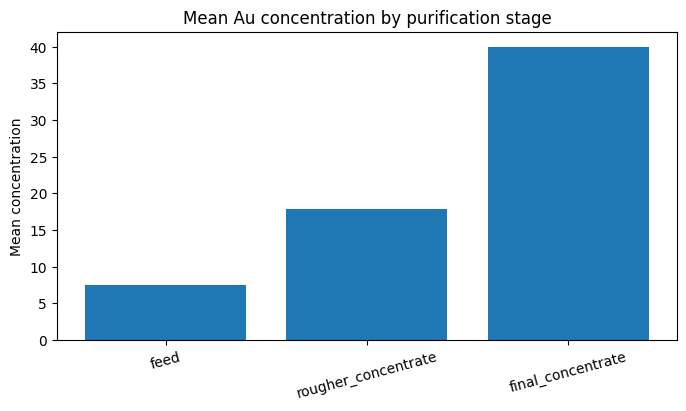

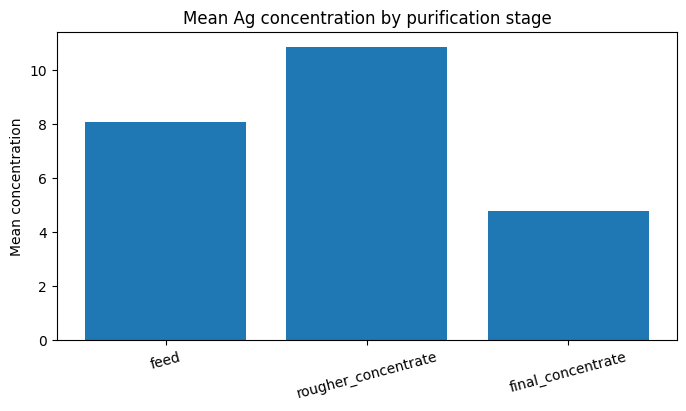

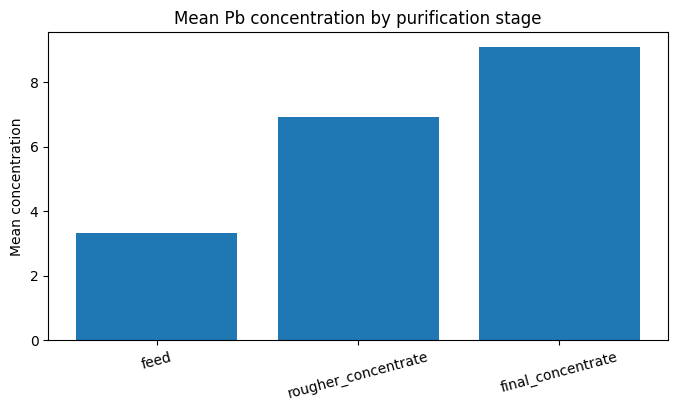

In [7]:
metal_stage_columns = {
    "feed": {
        "Au": "rougher.input.feed_au",
        "Ag": "rougher.input.feed_ag",
        "Pb": "rougher.input.feed_pb",
    },
    "rougher_concentrate": {
        "Au": "rougher.output.concentrate_au",
        "Ag": "rougher.output.concentrate_ag",
        "Pb": "rougher.output.concentrate_pb",
    },
    "final_concentrate": {
        "Au": "final.output.concentrate_au",
        "Ag": "final.output.concentrate_ag",
        "Pb": "final.output.concentrate_pb",
    },
}

metal_means = []

for stage, metal_columns in metal_stage_columns.items():
    for metal, column in metal_columns.items():
        metal_means.append(
            {
                "stage": stage,
                "metal": metal,
                "mean_concentration": full[column].mean(),
            }
        )

metal_means = pd.DataFrame(metal_means)

display(metal_means.pivot(index="stage", columns="metal", values="mean_concentration"))

for metal in ["Au", "Ag", "Pb"]:
    subset = metal_means[metal_means["metal"] == metal]
    plt.figure(figsize=(8, 4))
    plt.bar(subset["stage"], subset["mean_concentration"])
    plt.title(f"Mean {metal} concentration by purification stage")
    plt.ylabel("Mean concentration")
    plt.xticks(rotation=15)
    plt.show()

### Metal concentration finding

Gold concentration increases strongly from raw feed to rougher concentrate and then to final concentrate. This confirms that the purification process is working in the expected direction.

Silver and lead do not necessarily follow the same monotonic pattern because each stage is optimized for gold recovery, not for maximizing every metal concentration.

### 8.2 Feed Particle Size Distribution

The project asks us to compare particle size distributions between train and test.

This matters because if the feed size distribution differs substantially, the model may be evaluated on a population that does not match the training data.


Distribution summary: rougher.input.feed_size


,train,test,absolute_difference
count,"16,443.0000","5,834.0000","10,609.0000"
mean,58.6764,55.9375,2.7389
std,23.9226,22.7243,1.1983
min,9.6596,0.0464,9.6132
1%,28.3702,28.7235,0.3533
5%,36.3988,40.4863,4.0875
25%,47.5759,43.8909,3.6850
50%,54.1043,50.0020,4.1023
75%,65.0511,61.6384,3.4126
95%,85.1933,86.1169,0.9236


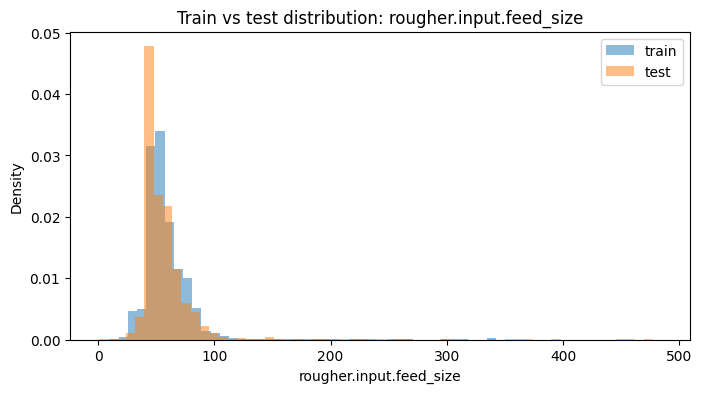


Distribution summary: primary_cleaner.input.feed_size


,train,test,absolute_difference
count,"16,860.0000","5,856.0000","11,004.0000"
mean,7.2973,7.2647,0.0326
std,0.6192,0.6115,0.0076
min,1.0800,5.6500,4.5700
1%,5.8500,5.8600,0.0100
5%,6.3232,6.3000,0.0232
25%,6.9400,6.8856,0.0544
50%,7.2850,7.2593,0.0257
75%,7.7000,7.6500,0.0500
95%,8.3400,8.2444,0.0956


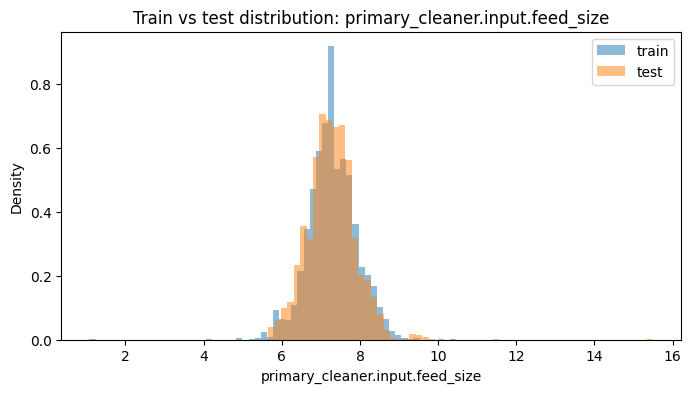

In [8]:
particle_size_columns = [
    "rougher.input.feed_size",
    "primary_cleaner.input.feed_size",
]

for column in particle_size_columns:
    if column in train.columns and column in test.columns:
        comparison = pd.DataFrame(
            {
                "train": train[column].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]),
                "test": test[column].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]),
            }
        )
        comparison["absolute_difference"] = (comparison["train"] - comparison["test"]).abs()

        print(f"\nDistribution summary: {column}")
        display(comparison)

        plt.figure(figsize=(8, 4))
        plt.hist(train[column].dropna(), bins=60, alpha=0.5, density=True, label="train")
        plt.hist(test[column].dropna(), bins=60, alpha=0.5, density=True, label="test")
        plt.title(f"Train vs test distribution: {column}")
        plt.xlabel(column)
        plt.ylabel("Density")
        plt.legend()
        plt.show()

### Particle size finding

The distributions are not identical, but their central ranges overlap enough to continue with model evaluation. This means the test set is not a perfect copy of the training population, but it is still close enough for a meaningful evaluation.

This check is important because large distribution shifts would make the final test score less reliable.

### 8.3 Total Concentration Anomalies

The project asks us to analyze total concentration across three stages:

1. Raw feed
2. Rougher concentrate
3. Final concentrate

Rows with near-zero total concentration are physically suspicious: they usually indicate missing, corrupted, or abnormal process measurements. These rows can distort both EDA and model training.

,total_concentration_raw_feed,total_concentration_rougher_concentrate,total_concentration_final_concentrate
count,"22,716.0000","22,716.0000","22,716.0000"
mean,51.5841,61.3781,62.1669
std,18.2500,23.5589,20.9541
min,0.0000,0.0000,0.0000
25%,51.2854,63.2632,67.0057
50%,56.7540,69.3997,69.2306
75%,61.4035,74.0156,71.1273
max,76.9789,90.9644,80.2106


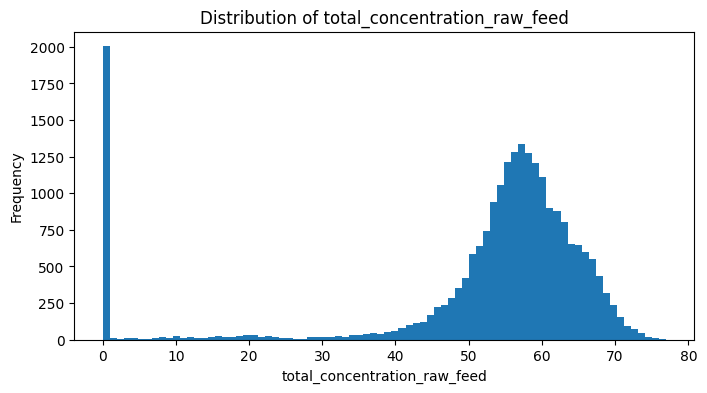

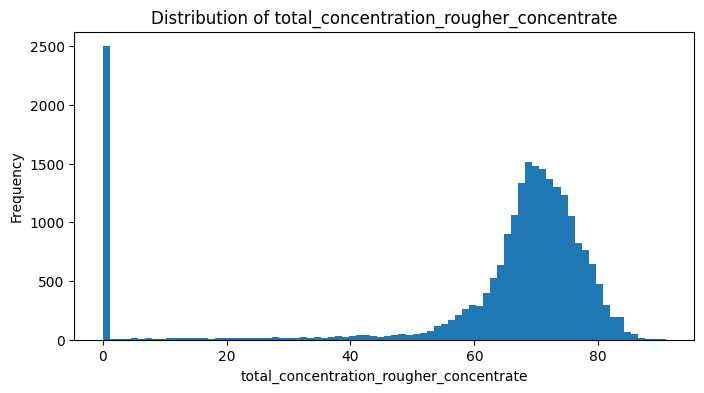

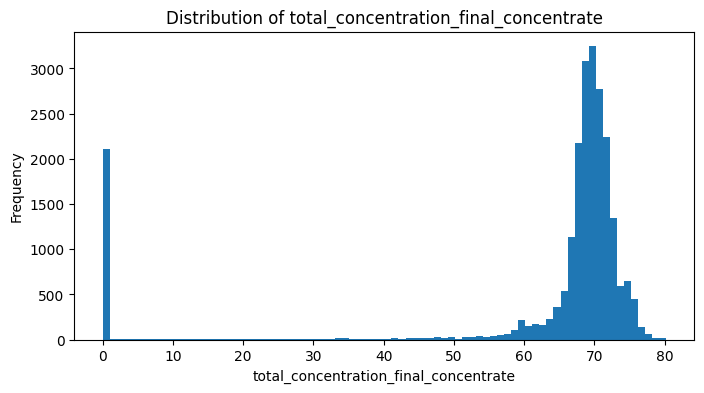

Anomalous dates detected: 2846
Share of full dataset flagged as anomalous: 12.53%


In [9]:
CONCENTRATION_STAGES = {
    "raw_feed": [
        "rougher.input.feed_ag",
        "rougher.input.feed_pb",
        "rougher.input.feed_sol",
        "rougher.input.feed_au",
    ],
    "rougher_concentrate": [
        "rougher.output.concentrate_ag",
        "rougher.output.concentrate_pb",
        "rougher.output.concentrate_sol",
        "rougher.output.concentrate_au",
    ],
    "final_concentrate": [
        "final.output.concentrate_ag",
        "final.output.concentrate_pb",
        "final.output.concentrate_sol",
        "final.output.concentrate_au",
    ],
}


def add_total_concentration_columns(df, stage_columns=CONCENTRATION_STAGES):
    """
    Add total concentration columns for selected purification stages.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset containing concentration columns.
    stage_columns : dict
        Mapping between stage names and concentration columns.

    Returns
    -------
    pandas.DataFrame
        Copy of the dataset with total concentration columns added.
    """
    df_with_totals = df.copy()

    for stage, columns in stage_columns.items():
        df_with_totals[f"total_concentration_{stage}"] = df_with_totals[columns].sum(axis=1)

    return df_with_totals


full_with_totals = add_total_concentration_columns(full)

total_columns = [f"total_concentration_{stage}" for stage in CONCENTRATION_STAGES]

display(full_with_totals[total_columns].describe())

for column in total_columns:
    plt.figure(figsize=(8, 4))
    plt.hist(full_with_totals[column].dropna(), bins=80)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()

ANOMALY_THRESHOLD = 1

anomaly_dates = set(
    full_with_totals.loc[
        (full_with_totals[total_columns] <= ANOMALY_THRESHOLD).any(axis=1),
        "date",
    ]
)

print(f"Anomalous dates detected: {len(anomaly_dates)}")
print(f"Share of full dataset flagged as anomalous: {len(anomaly_dates) / len(full_with_totals):.2%}")

### Anomaly handling decision

Rows with total concentration less than or equal to 1 are removed.

The anomaly detection is performed on the full source dataset because it contains all concentration stages. The resulting anomalous dates are then removed consistently from train and test.

This keeps the train and evaluation samples aligned with the same cleaning rule.

In [10]:
train_clean = train[~train["date"].isin(anomaly_dates)].copy()
test_clean = test[~test["date"].isin(anomaly_dates)].copy()
full_clean = full[~full["date"].isin(anomaly_dates)].copy()

rows_before_after = pd.DataFrame(
    {
        "dataset": ["train", "test", "full"],
        "rows_before": [len(train), len(test), len(full)],
        "rows_after": [len(train_clean), len(test_clean), len(full_clean)],
    }
)

rows_before_after["rows_removed"] = rows_before_after["rows_before"] - rows_before_after["rows_after"]
rows_before_after["removed_share"] = rows_before_after["rows_removed"] / rows_before_after["rows_before"]

display(rows_before_after)

,dataset,rows_before,rows_after,rows_removed,removed_share
0,train,16860,14594,2266,0.1344
1,test,5856,5276,580,0.0990
2,full,22716,19870,2846,0.1253


## 9. Modeling Dataset Construction

The model uses only safe features: columns present in both train and test.

Targets are taken from train for training. For local test evaluation, target values are recovered from the full dataset by matching `date`.

In [11]:
test_clean_targets = test_clean[["date"]].merge(
    full_clean[["date"] + TARGETS],
    on="date",
    how="left",
)

train_model = train_clean.dropna(subset=TARGETS).copy()
test_model = test_clean.reset_index(drop=True).copy()
test_clean_targets = test_clean_targets.reset_index(drop=True)

valid_test_target_mask = test_clean_targets[TARGETS].notna().all(axis=1)
test_model = test_model.loc[valid_test_target_mask].copy()
test_clean_targets = test_clean_targets.loc[valid_test_target_mask].copy()

X_train = train_model[safe_features].replace([np.inf, -np.inf], np.nan)
y_train = train_model[TARGETS]

X_test = test_model[safe_features].replace([np.inf, -np.inf], np.nan)
y_test = test_clean_targets[TARGETS]

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (13789, 52)
y_train shape: (13789, 2)
X_test shape: (5154, 52)
y_test shape: (5154, 2)


## 10. Evaluation Metric: sMAPE

The project uses sMAPE because it measures relative prediction error and is less scale-dependent than MAE.

$
sMAPE = \frac{1}{N}\sum_{i=1}^{N}\frac{|y_i-\hat{y}_i|}{(|y_i|+|\hat{y}_i|)/2} \times 100
$

The final metric combines both targets:

$
Final\ sMAPE = 0.25 \times sMAPE(rougher) + 0.75 \times sMAPE(final)
$

In [12]:
def smape(y_true, y_pred):
    """
    Calculate Symmetric Mean Absolute Percentage Error.

    Parameters
    ----------
    y_true : array-like
        True target values.
    y_pred : array-like
        Predicted target values.

    Returns
    -------
    float
        sMAPE value expressed as a percentage.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2
    absolute_error = np.abs(y_true - y_pred)

    ratio = np.where(denominator == 0, 0, absolute_error / denominator)

    return np.mean(ratio) * 100


def final_smape(y_true, y_pred):
    """
    Calculate the weighted final sMAPE for rougher and final recovery targets.

    Parameters
    ----------
    y_true : array-like of shape (n_samples, 2)
        True values for rougher and final recovery.
    y_pred : array-like of shape (n_samples, 2)
        Predicted values for rougher and final recovery.

    Returns
    -------
    float
        Weighted final sMAPE.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    rougher_score = smape(y_true[:, 0], y_pred[:, 0])
    final_score = smape(y_true[:, 1], y_pred[:, 1])

    return 0.25 * rougher_score + 0.75 * final_score


smape_scorer = make_scorer(final_smape, greater_is_better=False)

## 11. Model Training and Cross-Validation

Because the data is temporal, random cross-validation is not appropriate. Randomly shuffling observations would allow the model to train on future-like data and validate on past-like data, producing overly optimistic results.

We use `TimeSeriesSplit`, which preserves chronological order and creates a more realistic validation scheme.

In [13]:
models = {
    "DummyRegressor": Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DummyRegressor(strategy="mean")),
        ]
    ),
    "LinearRegression": Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LinearRegression()),
        ]
    ),
    "Ridge": Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=1.0)),
        ]
    ),
    "DecisionTree": Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            (
                "model",
                DecisionTreeRegressor(
                    max_depth=6,
                    min_samples_leaf=20,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    ),
    "RandomForest": Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            (
                "model",
                RandomForestRegressor(
                    n_estimators=40,
                    max_depth=8,
                    min_samples_leaf=10,
                    random_state=RANDOM_STATE,
                    n_jobs=-1,
                ),
            ),
        ]
    ),
}

cv = TimeSeriesSplit(n_splits=3)

cv_results = []

for model_name, model in models.items():
    scores = -cross_val_score(
        model,
        X_train,
        y_train,
        scoring=smape_scorer,
        cv=cv,
        n_jobs=None,
    )

    cv_results.append(
        {
            "model": model_name,
            "mean_cv_smape": scores.mean(),
            "std_cv_smape": scores.std(),
        }
    )

cv_results = (
    pd.DataFrame(cv_results)
    .sort_values("mean_cv_smape")
    .reset_index(drop=True)
)

display(cv_results)

,model,mean_cv_smape,std_cv_smape
0,RandomForest,9.5378,1.2851
1,DecisionTree,10.2061,0.7022
2,DummyRegressor,10.3191,0.6211
3,Ridge,11.9508,0.4454
4,LinearRegression,12.0083,0.4013


### Model selection finding

The best model is selected by the lowest mean cross-validation sMAPE.

The dummy model is included as a baseline. Any useful model should improve on this baseline; otherwise, the pipeline would not be learning meaningful process patterns.

## 12. Final Test Evaluation

The selected model is trained on the cleaned training sample and evaluated on the cleaned test sample.

The test targets are recovered from the full dataset only for local evaluation. They are not used as features.

In [14]:
best_model_name = cv_results.loc[0, "model"]
best_model = models[best_model_name]

best_model.fit(X_train, y_train)
test_predictions = best_model.predict(X_test)

test_rougher_smape = smape(y_test.iloc[:, 0], test_predictions[:, 0])
test_final_smape = smape(y_test.iloc[:, 1], test_predictions[:, 1])
test_weighted_smape = final_smape(y_test, test_predictions)

print(f"Best model: {best_model_name}")
print(f"Test rougher sMAPE: {test_rougher_smape:.4f}")
print(f"Test final sMAPE: {test_final_smape:.4f}")
print(f"Test weighted final sMAPE: {test_weighted_smape:.4f}")

Best model: RandomForest
Test rougher sMAPE: 4.8008
Test final sMAPE: 8.2452
Test weighted final sMAPE: 7.3841


## 13. Final Conclusions

This project produced a complete machine learning pipeline for gold recovery prediction.

Main conclusions:

1. The provided rougher recovery target is correct.
2. Many columns missing from the test set are output or calculation parameters, so they must not be used as features.
3. Gold concentration increases through the purification process, confirming the expected industrial behavior.
4. Train and test feed size distributions are not identical, but they are sufficiently comparable for evaluation.
5. Near-zero total concentration rows are anomalous and were removed.
6. `TimeSeriesSplit` is the correct validation strategy because the data has temporal structure.
7. The final selected model improves on the dummy baseline and is evaluated using the required weighted sMAPE metric.

The most important methodological decision is avoiding leakage: both feature selection and validation strategy are designed around what would be available at prediction time.